# APL Study Session 7

[BasedPL](https://github.com/AnswerDotAI/basedpl) (BPL) is an array language derived from APL, with ideas from J and BQN. Functions work on whole arrays, and small functions can be combined into larger ones. Its Rust implementation has a Python interface, so it can run inside SolveIt.

This dialogue starts with installation and a few short expressions, then moves on to plots, SVG and canvas animations. The examples are runnable code messages, with notes explaining what to look for.

## Installation

Install `basedpl`, then check the version. These examples were tested with BPL 0.1.55; the installation below pins that version to match the browser assets used for animation.

In [ ]:
from importlib.metadata import version
print('BPL', version('basedpl'))  # Installed automatically by CRAFT.ipynb

BPL 0.1.55


In [ ]:
!pip list | rg based

basedpl                0.1.55


## Running BPL in SolveIt

Keep SolveIt's normal Python kernel and load BPL's notebook extension. This lets you write BPL directly in code messages while keeping Python available for imports and data conversion.

Run the following message once per kernel session which registers the `%bpl` and `%%bpl` cell magics.

In [ ]:
# CRAFT.ipynb registers %%bpl automatically for this dialogue.
assert get_ipython().find_cell_magic('bpl') is not None

### BPL Symbol Entry

The BPL toolbar loads automatically from this folder's CRAFT files. It starts with 98 core symbols; choose All for all 150 entries, including superscripts, subscripts and other characters.

Click a glyph to insert it. In Code, insertion adds `%%bpl` when needed; the small BPL button beside Filter adds just the magic. Note, Prompt and Raw receive plain text. Browse provides search, help, examples, pinning, favourites and recently used entries.

Show or hide the toolbar with the BPL button beside Settings, Ctrl+Shift+8 on Windows or Cmd+Shift+8 on Mac. Backtick completion and direct Alt/Option glyph entry remain available. Run `setup_bpl()` to refresh the interface.

See README.md in this folder for controls, customisation and sharing. Duplicate a session in this folder to start the next lesson; the Craft setup is inherited automatically.

In [ ]:
# Refresh the shared Craft keyboard and toolbar if needed.
setup_bpl()

Javascript(// Based on Adám Brudzewsky's APL language bar: https://abrudz.github.io/lb
// MIT License, Copyright (c) 2011-2020 Nikolay G. Nikolov and Adam Brudzevski.
// BPL name completion, editor adapters, dark mode and overlay layout by Jeremy Howard.
((symbols, input, layout) => {
    const d = document;
    // Docs pages have no bar, except a page with a `data-bpl` editor, such as the playground.
    if (d.querySelector('.ngn_lb') || d.querySelector('meta[name=generator][content^=quarto]') && !d.querySelector('[data-bpl]')) return;

    const {inCode, bplStart, entry, press, reset} = input(symbols, layout);
    const shortcuts = new Map(symbols.map(({glyph, shortcut}) => [glyph, shortcut]));
    let leftAlt = false, rightAlt = false;

    function textareaRect(t) {
        const mirror = d.createElement('div'), caret = d.createElement('span'), css = getComputedStyle(t), rect = t.getBoundingClientRect();
        for (const p of ['font', 'lineHeight', 'letterSpacing', 'padding', 'bo

HTML(<style>/* Code fonts for the magics and the docs. The docs load this file through the symlink nbs/fonts.css. */
:root { --bpl-font: SAX2B; --apl-font: BQN386; }
@font-face { font-family: SAX2B; src: local("SAX2B"), url("https://cdn.jsdelivr.net/gh/AnswerDotAI/basedpl@main/nbs/fonts/SAX2B.woff2") format("woff2"); }
@font-face { font-family: BQN386; src: local("BQN386"), url("https://cdn.jsdelivr.net/gh/dzaima/BQN386@master/BQN386.woff2") format("woff2"); }
.bpl_out { font-family: var(--bpl-font), monospace !important; line-height: 1.05 !important; }
.bpl_choices button[aria-selected="true"]{background:#2463a8;color:white}</style>)

Javascript((()=>{
    const bar=document.querySelector('.ngn_lb'); if(bar) bar.hidden=false;
    let button=document.getElementById('bpl-symbol-toggle');
    if(!button){
        button=document.createElement('button'); button.id='bpl-symbol-toggle';
        button.type='button'; button.textContent='BPL';
        button.title='Show or hide BPL symbols';
        button.className='uk-btn uk-btn-sm uk-btn-default cursor-pointer';
        document.getElementById('settings').before(button);
    }
    button.setAttribute('aria-pressed',String(bar && !bar.hidden));
    button.onclick=()=>{
        const current=document.querySelector('.ngn_lb');
        if(current){current.hidden=!current.hidden;button.setAttribute('aria-pressed',String(!current.hidden));}
    };
    })();)

Javascript(/*
Third-party attribution and licence texts

# Third-Party Notices

The generated keyboard integration in `CRAFT.js` includes code and symbol/layout
metadata from BasedPL 0.1.61 (Answer.AI and contributors), distributed under
Apache-2.0. Its licence is reproduced in `the Apache-2.0 text below`.
Source: https://github.com/AnswerDotAI/basedpl

BasedPL's browser language bar is based on Adam Brudzewsky's APL language bar.
The source identifies copyright (c) 2011-2020 Nikolay G. Nikolov and Adam
Brudzevski under the MIT licence, reproduced in `the MIT text below`.
Source: https://abrudz.github.io/lb/

Local changes add completion selection with arrow keys, support the animation
magic header, and integrate the language bar with the custom SolveIt palette.
The generated code retains its upstream attribution comments.

The notebooks contain personal study notes and examples following Jeremy
Howard's APL study group. Screenshots and quoted teaching material remain
attributable to t

## Operators in APL

**All operators return a function.** That's the definition of an operator in APL.

An operator takes one or two operands (functions or arrays) and produces a **derived function**. For example, `/` takes `+` and produces `+/`, the sum function. Applying that function to `1 2 3` gives `6`.

## Custom Operators

An approximate of the derivative as Jeremy discussed in the video is given as follows.
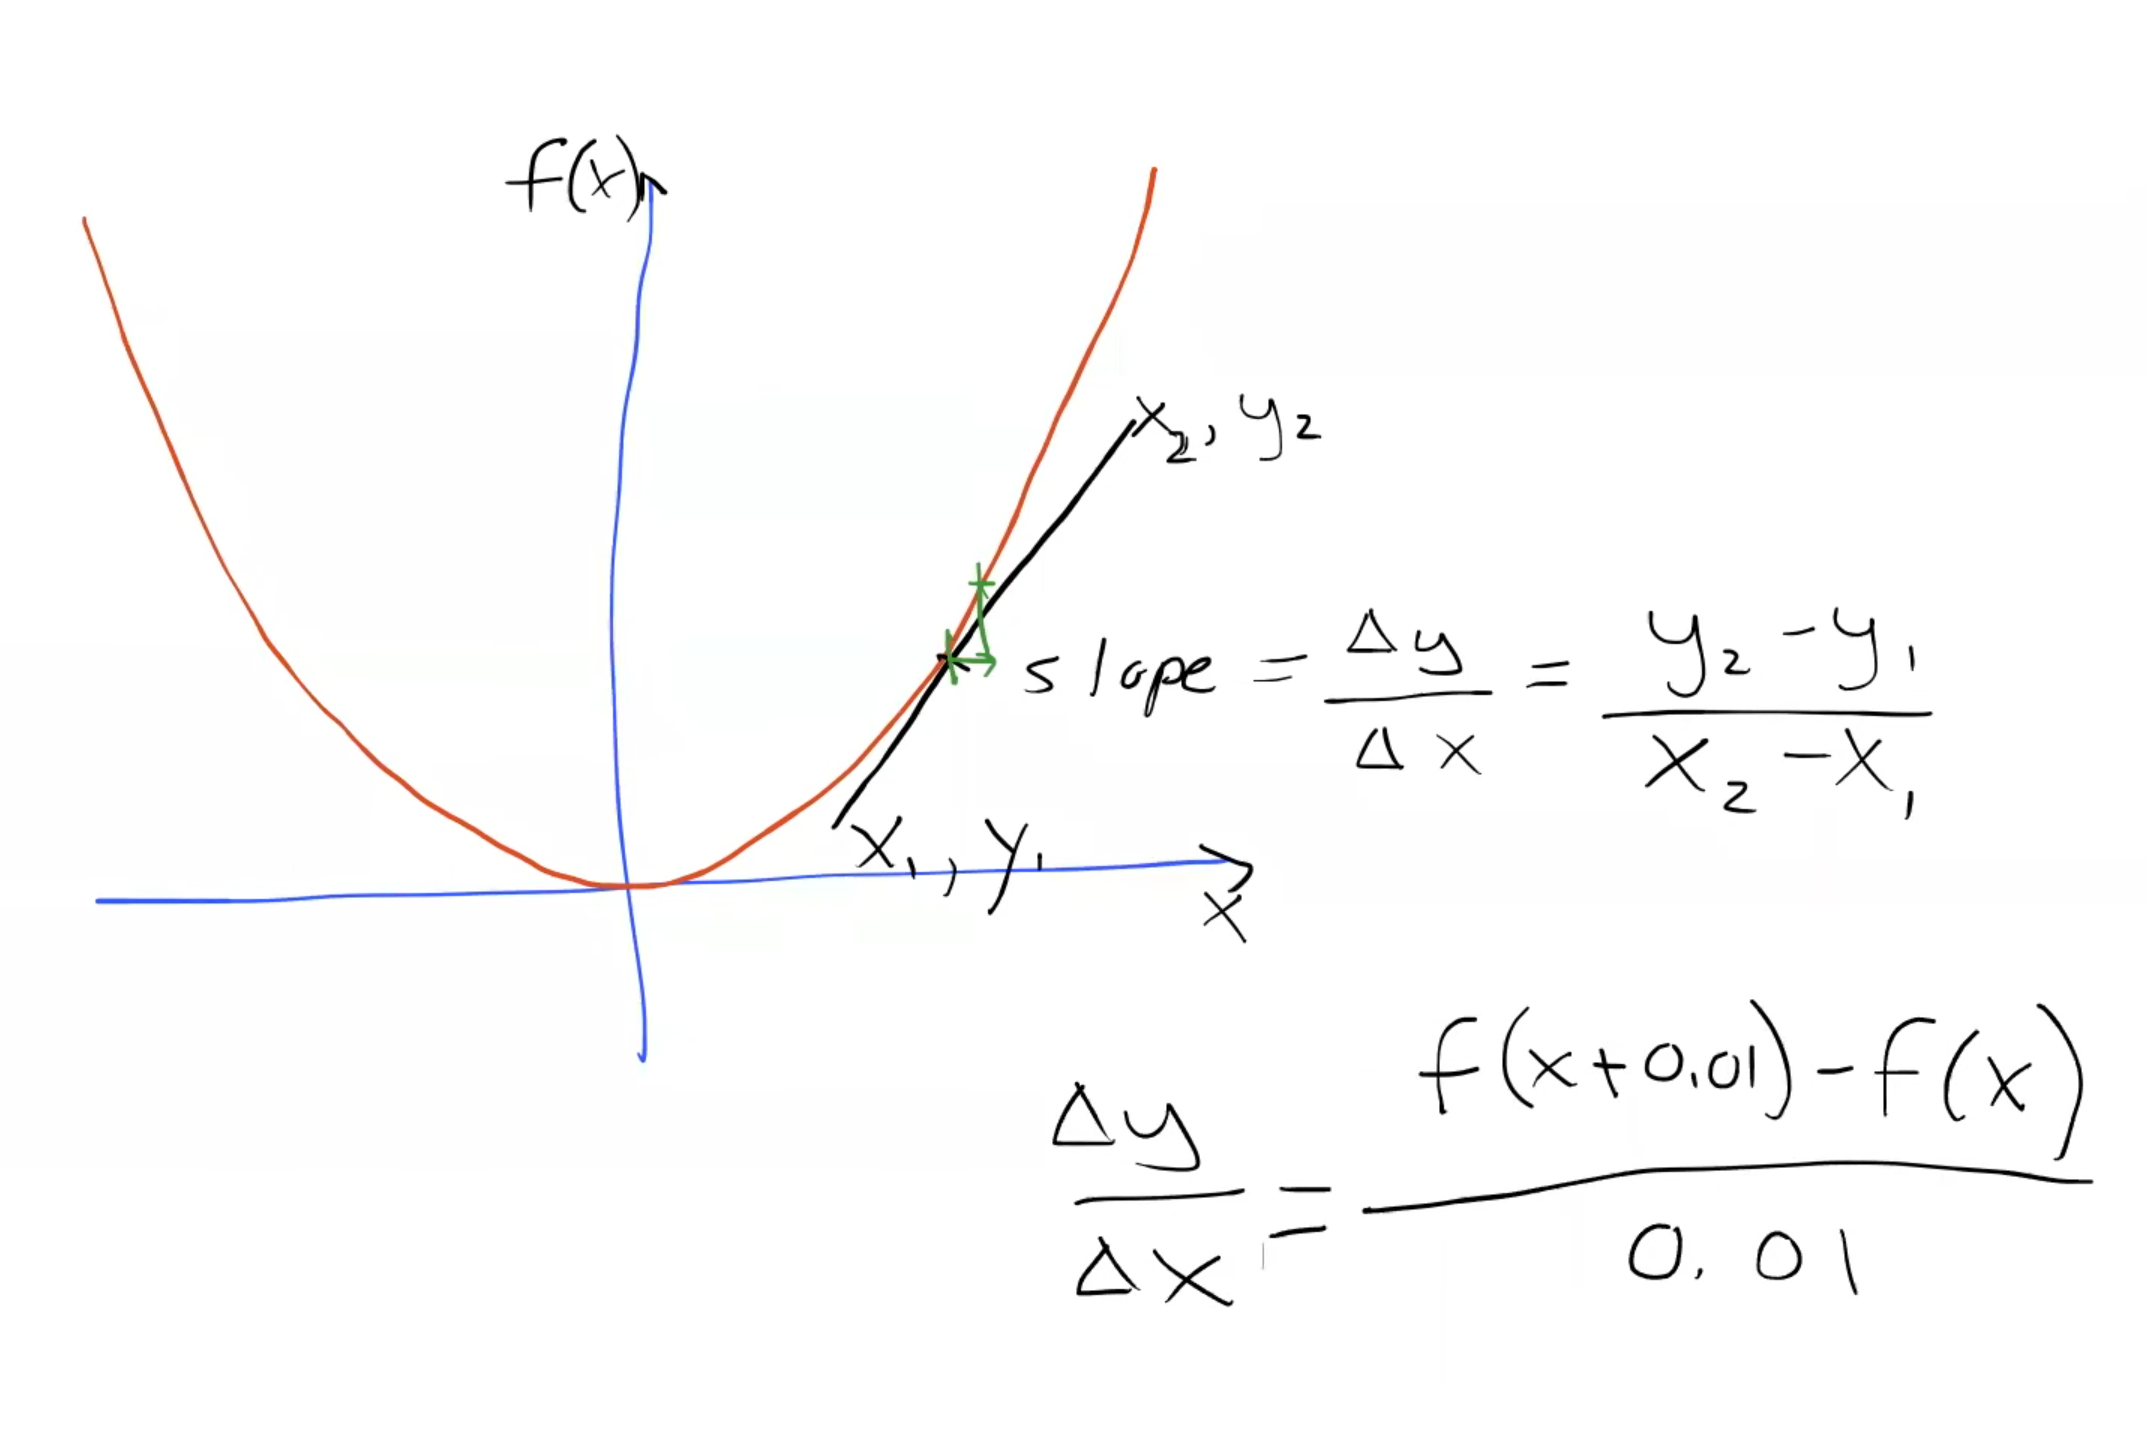

The idea is to try and implement this in BPL.

First though, let's remind ourselves what a basic function looks like in APL.

In [ ]:
%%bpl
⍝ Here is the function f(x) = x^2 implemented in APL
f ← {⍵*2}
f 3

9

We can also do things like this.

In [ ]:
%%bpl
f ← *
2 f 3

8

`f ← *` gives the existing power function another name (an alias), so `2 f 3` means `2*3` and returns `8`.

Curly brackets define a new function body, which runs when called. `{*}` returns the function `*` itself; `{⍺*⍵}` uses the supplied arguments to calculate the power.

In [ ]:
%%bpl
sum ← +/
sum 1 2 3

6

This is the same as doing:

In [ ]:
%%bpl
sum ← {+/⍵}
sum 1 2 3

6

We're starting to build a custom operator for differentiating functions. First, we'll estimate the slope of `f(x)=x²` at `x=3` using a small forward step `d`. In BPL, `f ← *↢2` fixes the exponent at `2`, matching Jeremy's APL `f ← *∘2`. The two examples move closer to the exact derivative, `6`. We'll turn this calculation into an operator in the next lesson.

In [ ]:
%%bpl
f ← *↢2

In [ ]:
%%bpl
d ← 0.01
x ← 3
((f (x+d)) - f x) ÷ d

6.01

In [ ]:
%%bpl
d ← 0.0001
((f (x+d)) - f x) ÷ d

6.0001

In [ ]:
%%bpl
grad ← {((f ⍺+⍵) - f ⍺) ÷ ⍵}

In [ ]:
%%bpl
3 grad 0.01

6.01

In [ ]:
%%bpl
grad ← {((⍶ (⍺+⍵)) - ⍶ ⍺) ÷ ⍵}
3 grad 0.01
3 f grad 0.01

0 ¯299

6.01

Previously, `grad` always used the named function `f`. Replacing `f` with `⍶` makes `grad` an **operator**: it accepts a function and builds a new function from it. BPL uses `⍶` (alpha underbar) for Jeremy's APL `⍺⍺`.

Read `3 f grad 0.01` as `3 (f grad) 0.01`:

- `f grad` builds a slope-estimating function for `f`. Inside the braces, `⍶` means that supplied function.
- `3` becomes `⍺`: the point where we estimate the slope.
- `0.01` becomes `⍵`: the small step size.

With `f` defined as square, the body calculates `(f(3.01) - f(3)) ÷ 0.01`, giving `(9.0601 - 9) ÷ 0.01 = 6.01`. The exact slope is 6; this is an approximation.

The function is called an **operand** of the operator; the two numbers are **arguments** of the function it builds. You can supply another function in place of `f` without rewriting `grad`. [BPL operator notation](https://answerdotai.github.io/basedpl/dfns.html#operators).

In [ ]:
%%bpl
⍝ A function that always uses inc
inc ← {⍵+1}
twice ← {inc inc ⍵}
twice 3                 ⍝ 3 → 4 → 5

5

In [ ]:
%%bpl
⍝ Redefine twice as an operator: supply the function to repeat
twice ← {⍶ ⍶ ⍵}
inc twice 3             ⍝ 3 → 4 → 5
- twice 3               ⍝ 3 → ¯3 → 3

5

3

`⍶` (alpha underbar) is the special name for the left operand; it is not itself an operator. Using it in the braces makes `twice` or `grad` an operator. `inc twice` builds a function that applies `inc` twice; `- twice` builds one that negates twice. The previous function definition of `twice` has been replaced.

Your `3 grad 0.01` is read as **`(3 grad) 0.01`**. It supplies the number `3` as the operand (`⍶`), then calls the resulting function with one argument, `⍵ = 0.01`. There is no left argument `⍺`. It is not a dyadic call to `grad`.

BPL permits value operands, but this gradient body expects a function. With the number `3` supplied:

1. BPL's absent-left-argument rule reduces `⍺+⍵` to `⍵`.
2. `⍶ (⍺+⍵)` becomes the two-item list `3 0.01`, rather than a function call.
3. `⍶ ⍺` reduces to `3`.
4. Subtracting gives `0 ¯2.99`; dividing by `0.01` gives **`0 ¯299`**.

That is valid list arithmetic, but not a derivative estimate. For the intended calculation, use **`3 (f grad) 0.01`**: `f` is the operand, `3` is `⍺`, and `0.01` is `⍵`. [BPL arguments and operators](https://answerdotai.github.io/basedpl/dfns.html#arguments).

In [ ]:
%%bpl
inc ← {⍵+1}
double ← {2×⍵}
pipe ← {⍶ (⍹ ⍵)}

(inc pipe double) 3      ⍝ double 3 → 6; inc 6 → 7

7

In [ ]:
%%bpl
(double pipe inc) 3      ⍝ inc 3 → 4; double 4 → 8

8

`⍶` (alpha underbar) is the left operand; `⍹` (omega underbar) is the right operand. Here both operands are functions. Ordinary `⍵` is the argument passed to the function that the operator builds.

Read `pipe ← {⍶ (⍹ ⍵)}` as: apply the right operand to the input, then apply the left operand to that result.

- `(inc pipe double) 3`: `⍶ = inc`, `⍹ = double`, `⍵ = 3`. Double 3 to get 6, then increment to get **7**.
- `(double pipe inc) 3`: the operands swap. Increment 3 to get 4, then double to get **8**.

`pipe` is a **dyadic operator** because it takes two operands. Each derived function is called **monadically** here because it receives one argument, `3`. [BPL operators](https://answerdotai.github.io/basedpl/dfns.html#operators).

### ⍨ (Tilde Diaeresis)

#### Dyadic ⍨ (Commute)

In [ ]:
%%bpl
3-2

1

In [ ]:
%%bpl
2-3

¯1

In [ ]:
%%bpl
3-⍨2

¯1

In [ ]:
%%bpl
grad ← {⍵ ÷⍨ (⍶ (⍺+⍵)) - ⍶ ⍺}
3 f grad 0.01

6.01

Read `⍵ ÷⍨ ...` as "omega divided into the result on the right". The whole subtraction to the right is evaluated first; `÷⍨` then divides that result by `⍵`. Moving the difference to the right lets us remove its surrounding parentheses. Be careful: `⍨` swaps the two arguments after normal grouping; it does not gather everything on both sides. In the original `(difference) ÷ ⍵`, the parentheses are needed to keep the whole difference as the left argument.

In [ ]:
%%bpl
zero ← 0
zero 9
2 zero 5

0 9

2 0 5

In [ ]:
%%bpl
zero ← 0⍨
zero 9
2 zero 5

0

0

Same as:

In [ ]:
%%bpl
zero ← {0⍨ ⍵}
zero 9
2 zero 5

0

0

### ¨ (Diaeresis)

#### Monadic ¨ (Each)

In [ ]:
%%bpl
⎕ ← a ← [[1 2 3 4] [5 6 7]]

┌→──────────────────┐
│ ┌→──────┐ ┌→────┐ │
│ │1 2 3 4│ │5 6 7│ │
│ └~──────┘ └~────┘ │
└∊──────────────────┘

In [ ]:
%%bpl
+/¨a

10 18

In [ ]:
%%bpl
⎕ ← b ← [[1 2 3] [4 5 6]]

┌→────────────────┐
│ ┌→────┐ ┌→────┐ │
│ │1 2 3│ │4 5 6│ │
│ └~────┘ └~────┘ │
└∊────────────────┘

In [ ]:
%%bpl
2 3 +¨ b

┌→────────────────┐
│ ┌→────┐ ┌→────┐ │
│ │3 4 5│ │7 8 9│ │
│ └~────┘ └~────┘ │
└∊────────────────┘

### ⌿ (Slash Bar)

#### Monadic ⌿ (Reduce First)

In [ ]:
%%bpl
mat ← 2 3 ⍴ ↦6     ⍝ BPL: ↦6 gives 1 2 3 4 5 6
+/mat

6 15

In [ ]:
%%bpl
+⌿mat

5 7 9

`⌿` (Reduce First) works like `/` (Reduce), but chooses a different axis by default. For our matrix:

```text
1 2 3
4 5 6
```

Its shape is `2 3`: axis **0** is the row index (two rows), and axis **1** is the column index (three columns). Reducing an axis combines the entries along that direction and removes that axis.

| Expression | Axis reduced | Calculation | Result |
|---|---|---|---|
| `+/mat` | Last: axis 1 | Across each row: `1+2+3`, `4+5+6` | `6 15` |
| `+⌿mat` | First: axis 0 | Down each column: `1+4`, `2+5`, `3+6` | `5 7 9` |

The distinction is between the axis we **collapse** and the sums we **keep**. A row sum collapses the column axis; a column sum collapses the row axis. "First" means the first axis of the input (axis 0 in BPL), so `⌿` is correctly named.

The example uses BPL's `↦6` to get `1` through `6`; BPL's `⍳6` starts at zero. [BPL Reduce First reference](https://answerdotai.github.io/basedpl/glyphs/slash-bar.html).